In [1]:
#!/usr/bin/env python
# coding: utf-8

# parameters
DEVICE = 'cpu'
MODEL  = 'dm_mlp'

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.distributions as TD
import matplotlib
#matplotlib.use('Agg')
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import gaussian_kde
from tqdm import tqdm
from IPython.display import clear_output
import random, os, sys
sys.path.append('/home/arc/Projects/')
sns.set_theme(style="ticks", palette="pastel")

from OFM.ofmsrc.dgm_utils import visualize_2d_samples_groups, visualize_2d_map
from OFM.ofmsrc.tools import EMA
from OFM.ofmsrc.distributions import Sampler, StandardNormalSampler


In [2]:

def seed_everything(seed=42):
    np.random.seed(seed)
    torch.random.manual_seed(seed)
    random.seed(seed)


# ── Gaussian Mixture Sampler ──────────────────────────────────────────────────

class GaussianMixture(Sampler):
    """
    parameters: list of dicts with keys:
        "mean" : list of length dim
        "std"  : list of length dim  (diagonal covariance)
    All components equally weighted.
    """
    def __init__(self, parameters, device='cpu'):
        super().__init__(device=device)
        self.dim   = len(parameters[0]["mean"])
        self.means = torch.tensor(
            [p["mean"] for p in parameters], dtype=torch.float32, device=device)
        self.stds  = torch.tensor(
            [p["std"]  for p in parameters], dtype=torch.float32, device=device)
        self.K = len(parameters)
        self.means_np = self.means.cpu().numpy()
        self.stds_np  = self.stds.cpu().numpy()

    def sample(self, batch_size=10):
        idx   = torch.randint(0, self.K, (batch_size,), device=self.device)
        means = self.means[idx]
        stds  = self.stds[idx]
        return means + stds * torch.randn(batch_size, self.dim, device=self.device)

    def sample_np(self, n):
        return self.sample(n).cpu().numpy()



In [3]:
# ── PyTorch Port of Drift Loss ────────────────────────────────────────────────

def cdist_pytorch(x, y, eps=1e-8):
    # [B, N, D] x [B, M, D] -> [B, N, M]
    xydot = torch.einsum("bnd,bmd->bnm", x, y)
    xnorms = torch.einsum("bnd,bnd->bn", x, x)
    ynorms = torch.einsum("bmd,bmd->bm", y, y)
    # distance = sqrt(x^2 + y^2 - 2xy)
    sq_dist = xnorms[:, :, None] + ynorms[:, None, :] - 2 * xydot
    return torch.sqrt(torch.clamp(sq_dist, min=eps))

def drift_loss_pytorch(
        gen,
        fixed_pos,
        fixed_neg=None,
        weight_gen=None,
        weight_pos=None,
        weight_neg=None,
        R_list=(0.02, 0.05, 0.2),
        friction_coeff=0.0,
):
    """
    PyTorch port of the JAX drift_loss.

    friction_coeff : float in [0, 1]
        Friction coefficient that opposes the drift force.
        F_friction = -friction_coeff * F_drift, directed toward the previous
        (detached) particle position.
          0.0  → pure drift (default, original behaviour)
          1.0  → full friction, particles do not move
    """
    B, C_g, S = gen.shape
    C_p = fixed_pos.shape[1]

    if fixed_neg is None:
        fixed_neg = torch.zeros((B, 0, S), device=gen.device, dtype=gen.dtype)
    C_n = fixed_neg.shape[1]

    if weight_gen is None:
        weight_gen = torch.ones((B, C_g), device=gen.device, dtype=gen.dtype)
    if weight_pos is None:
        weight_pos = torch.ones((B, C_p), device=gen.device, dtype=gen.dtype)
    if weight_neg is None:
        weight_neg = torch.ones((B, C_n), device=gen.device, dtype=gen.dtype)

    old_gen = gen.detach()
    targets = torch.cat([old_gen, fixed_neg, fixed_pos], dim=1)
    targets_w = torch.cat([weight_gen, weight_neg, weight_pos], dim=1)

    with torch.no_grad():
        dist = cdist_pytorch(old_gen, targets)
        weighted_dist = dist * targets_w[:, None, :]
        scale = weighted_dist.mean(dim=(1, 2)) / targets_w.mean(dim=1) # [B]

        info = {"scale": scale.mean()}

        scale_inputs = torch.clamp(scale / np.sqrt(S), min=1e-3)
        old_gen_scaled = old_gen / scale_inputs[:, None, None]
        targets_scaled = targets / scale_inputs[:, None, None]

        dist_normed = dist / torch.clamp(scale[:, None, None], min=1e-3)

        mask_val = 100.0
        diag_mask = torch.eye(C_g, device=gen.device, dtype=gen.dtype)
        block_mask = F.pad(diag_mask, (0, C_n + C_p))
        block_mask = block_mask.unsqueeze(0)
        dist_normed = dist_normed + block_mask * mask_val

        force_across_R = torch.zeros_like(old_gen_scaled)

        for R in R_list:
            logits = -(dist_normed / R)
            affinity = F.softmax(logits, dim=-1)
            aff_transpose = F.softmax(logits, dim=-2)
            affinity = torch.sqrt(torch.clamp(affinity * aff_transpose, min=1e-6))
            affinity = affinity * targets_w[:, None, :]

            split_idx = C_g + C_n
            aff_neg = affinity[:, :, :split_idx]
            aff_pos = affinity[:, :, split_idx:]

            sum_pos = torch.sum(aff_pos, dim=-1, keepdim=True)
            r_coeff_neg = -aff_neg * sum_pos
            sum_neg = torch.sum(aff_neg, dim=-1, keepdim=True)
            r_coeff_pos = aff_pos * sum_neg

            R_coeff = torch.cat([r_coeff_neg, r_coeff_pos], dim=2)
            total_force_R = torch.einsum("biy,byx->bix", R_coeff, targets_scaled)

            total_coeffs = R_coeff.sum(dim=-1)
            total_force_R = total_force_R - total_coeffs[..., None] * old_gen_scaled
            f_norm_val = (total_force_R ** 2).mean(dim=(1, 2))

            info[f"loss_{R}"] = f_norm_val.mean()

            force_scale = torch.sqrt(torch.clamp(f_norm_val, min=1e-8))
            force_across_R = force_across_R + total_force_R / force_scale[:, None, None]

        # Friction force: opposes drift, directed toward previous position.
        # F_net = F_drift + F_friction = F_drift - friction_coeff * F_drift
        #       = (1 - friction_coeff) * F_drift
        effective_force = (1.0 - friction_coeff) * force_across_R
        info["friction_coeff"] = friction_coeff

        goal_scaled = old_gen_scaled + effective_force

    gen_scaled = gen / scale_inputs[:, None, None]
    diff = gen_scaled - goal_scaled
    loss = torch.mean(diff ** 2)

    return loss, info


In [4]:
# ── Model ─────────────────────────────────────────────────────────────────────

class MLP(nn.Module):
    def __init__(self, dim=2, dimh=1024, num_hidden_layers=2):
        super().__init__()
        layers = []
        layers.append(nn.Linear(dim, dimh))
        layers.append(nn.ReLU())
        for _ in range(num_hidden_layers - 1):
            layers.append(nn.Linear(dimh, dimh))
            layers.append(nn.ReLU())
        layers.append(nn.Linear(dimh, dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)



In [5]:
# ── Distributions ─────────────────────────────────────────────────────────────

seed_everything()

parameters = [
    {"mean": [0, 0],  "std": [1,   1  ]},
    {"mean": [3, 2],  "std": [0.5, 0.5]},
]
mixture        = GaussianMixture(parameters, device=DEVICE)
source_sampler = StandardNormalSampler(device=DEVICE)
target_sampler = mixture


In [6]:

# ── Scale diagnostics: what R values make sense? ──────────────────────────────
#
# R operates on *normalized* distances: dist_normed = dist / scale
# where scale = mean pairwise distance between gen particles and targets.
#
# So R is a fraction of the mean pairwise distance.
# We want R values that correspond to:
#   - within-component scale  (fine structure)
#   - between-component scale (global structure)
# ... all expressed as fractions of the mean pairwise distance.

N_DIAG = 2000

with torch.no_grad():
    src_samples = source_sampler.sample(N_DIAG).cpu().numpy()   # at t=0, gen ~ source
    tgt_samples = target_sampler.sample(N_DIAG).cpu().numpy()

# ── 1. Mean pairwise distance between source and target (= expected `scale`) ──
from scipy.spatial.distance import cdist

# Subsample for speed
idx_s = np.random.choice(N_DIAG, 500, replace=False)
idx_t = np.random.choice(N_DIAG, 500, replace=False)
cross_dists = cdist(src_samples[idx_s], tgt_samples[idx_t])
mean_pairwise = cross_dists.mean()
print(f"Expected scale (mean pairwise src↔tgt dist): {mean_pairwise:.3f}")

# ── 2. Characteristic scales of the target distribution ───────────────────────
K = len(parameters)
means = np.array([p["mean"] for p in parameters])
stds  = np.array([p["std"]  for p in parameters])

# Within-component: mean intra-cluster distance ≈ std * sqrt(pi/2) * sqrt(dim) for isotropic
dim = 2
within_scales = np.mean(stds, axis=1) * np.sqrt(np.pi / 2) * np.sqrt(dim)
print(f"\nWithin-component scales (expected intra-cluster dist):")
for k, ws in enumerate(within_scales):
    print(f"  Component {k}: {ws:.3f}  (raw std={stds[k]})")

# Between-component: pairwise distances between means
between_scales = []
for i in range(K):
    for j in range(i+1, K):
        d = np.linalg.norm(means[i] - means[j])
        between_scales.append(d)
        print(f"\nBetween-component dist (μ{i} ↔ μ{j}): {d:.3f}")

# ── 3. Express as fractions of mean_pairwise → these are your natural R values ─
print(f"\n── Suggested R values (scale / mean_pairwise) ──")
all_scales = list(within_scales) + between_scales
all_labels = [f"within-comp-{k}" for k in range(K)] + \
             [f"between-comp-{i}{j}" for i in range(K) for j in range(i+1,K)]
suggested_R = []
for label, s in zip(all_labels, all_scales):
    r = s / mean_pairwise
    suggested_R.append(r)
    print(f"  R={r:.3f}  ← {label}  (abs scale={s:.3f})")

print(f"\nCurrent R_list:   {(0.02, 0.05, 0.2)}")
print(f"Suggested R_list: {tuple(round(r, 2) for r in suggested_R)}")


Expected scale (mean pairwise src↔tgt dist): 2.742

Within-component scales (expected intra-cluster dist):
  Component 0: 1.772  (raw std=[1. 1.])
  Component 1: 0.886  (raw std=[0.5 0.5])

Between-component dist (μ0 ↔ μ1): 3.606

── Suggested R values (scale / mean_pairwise) ──
  R=0.647  ← within-comp-0  (abs scale=1.772)
  R=0.323  ← within-comp-1  (abs scale=0.886)
  R=1.315  ← between-comp-01  (abs scale=3.606)

Current R_list:   (0.02, 0.05, 0.2)
Suggested R_list: (np.float64(0.65), np.float64(0.32), np.float64(1.32))


In [7]:
# ── Model & Optimizer ─────────────────────────────────────────────────────────

seed_everything()

def get_model(name):
    model = MLP(dim=2, dimh=256, num_hidden_layers=3).to(DEVICE)
    return model

model = get_model(MODEL).to(DEVICE)
optim = torch.optim.Adam(model.parameters(), lr=5e-4)



In [8]:
# ── Output directory ──────────────────────────────────────────────────────────

EXP_DIR = f'./gaumix_{MODEL}'
os.makedirs(EXP_DIR, exist_ok=True)

samples_path    = os.path.join(EXP_DIR, 'samples.png')
curr_model_path = os.path.join(EXP_DIR, 'model.pth')
loss_path       = os.path.join(EXP_DIR, 'loss.png')



Iteration 10000  |  Loss: 7.1905  |  Friction: 0.000


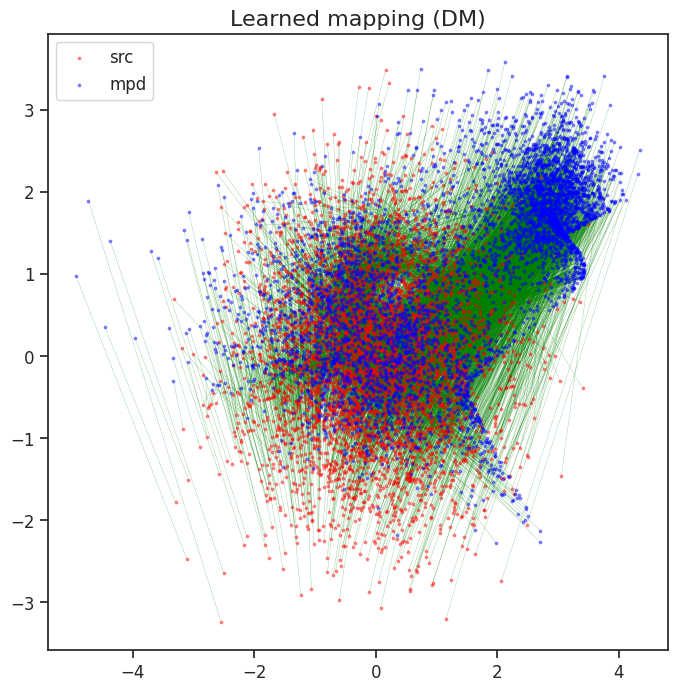

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████| 10000/10000 [01:04<00:00, 154.85it/s, friction=0, loss=7.19, scale=2.5]


In [9]:
# ── Training ──────────────────────────────────────────────────────────────────

MAX_ITER      = 10000
BATCH_SIZE    = 16
FRICTION_ON = False

ema          = EMA(0, betas=[0.999, 0.99])
loss_history = []


print('Fitting the Gaussian Mixture with Drifting Model')
with tqdm(range(MAX_ITER)) as tbar:
    for iteration in tbar:
        X = source_sampler.sample(BATCH_SIZE).to(DEVICE)
        Y_target = target_sampler.sample(BATCH_SIZE).to(DEVICE)

        # Generator samples
        Y_gen = model(X)

        # Friction increases linearly from 0 → 1 over training if ON
        
        if FRICTION_ON:
            friction_coeff = iteration / (MAX_ITER - 1)
        else:
            friction_coeff = 0
            
        # Compute drift loss
        loss, info = drift_loss_pytorch(
            Y_gen.unsqueeze(0),
            Y_target.unsqueeze(0),
            R_list=(0.02, 0.05, 0.1),
            friction_coeff=friction_coeff,
        )

        optim.zero_grad()
        loss.backward()
        optim.step()

        ema(model)

        loss_history.append(loss.item())
        tbar.set_postfix(loss=loss.item(), scale=info["scale"].item(), friction=friction_coeff)

        if (iteration + 1) % 500 == 0:
            clear_output(wait=True)
            print(f"Iteration {iteration+1}  |  Loss: {loss.item():.4f}  |  Friction: {friction_coeff:.3f}")
            plt.figure(figsize=(6, 4))
            plt.plot(loss_history); plt.yscale('log')
            plt.title('Loss History')
            plt.savefig(loss_path); plt.close()

            with torch.no_grad():
                X_vis = source_sampler.sample(5000).to(DEVICE)
                Y_vis = model(X_vis)
            visualize_2d_map(
                X_vis.cpu().numpy(), Y_vis.cpu().numpy(), 'Learned mapping (DM)',
                data_label='src', mapped_data_label='mpd',
                s=3, figsize=(8, 8), save_path=samples_path)

            torch.save(model.state_dict(), curr_model_path)
            for beta in [0.999, 0.99]:
                torch.save(ema.get_model(beta),
                           os.path.join(EXP_DIR, f'model_{beta}.pth'))


In [10]:
# ═══════════════════════════════════════════════════════════════════════════════
# POST-TRAINING ANALYSIS
# ═══════════════════════════════════════════════════════════════════════════════

N_GEN    = 500
N_STEPS  = 100
time_pts = np.linspace(0.0, 1.0, N_STEPS)

model.eval()
with torch.no_grad():
    x0_np  = source_sampler.sample(N_GEN).cpu().numpy()
    x0_t   = torch.tensor(x0_np, dtype=torch.float32).to(DEVICE)
    x1_t   = model(x0_t)
    x1_np  = x1_t.cpu().numpy()

# straight interpolation for visualization (similar to OFM)
trajectory = np.stack(
    [(1 - t) * x0_np + t * x1_np for t in time_pts], axis=0
)
velocity_const = x1_np - x0_np


# ── Helper: angle-based point colors ──────────────────────────────────────────

def get_angle_colors(positions):
    angles     = np.arctan2(positions[:, 1], positions[:, 0])
    angles_deg = (np.degrees(angles) + 360) % 360
    colors     = np.zeros((len(positions), 3))
    for i, angle in enumerate(angles_deg):
        seg   = int(angle / 120)
        local = angle - seg * 120
        if   seg == 0: colors[i] = [1 - local/120, local/120, 0]
        elif seg == 1: colors[i] = [0, 1 - local/120, local/120]
        else:          colors[i] = [local/120, 0, 1 - local/120]
    return colors



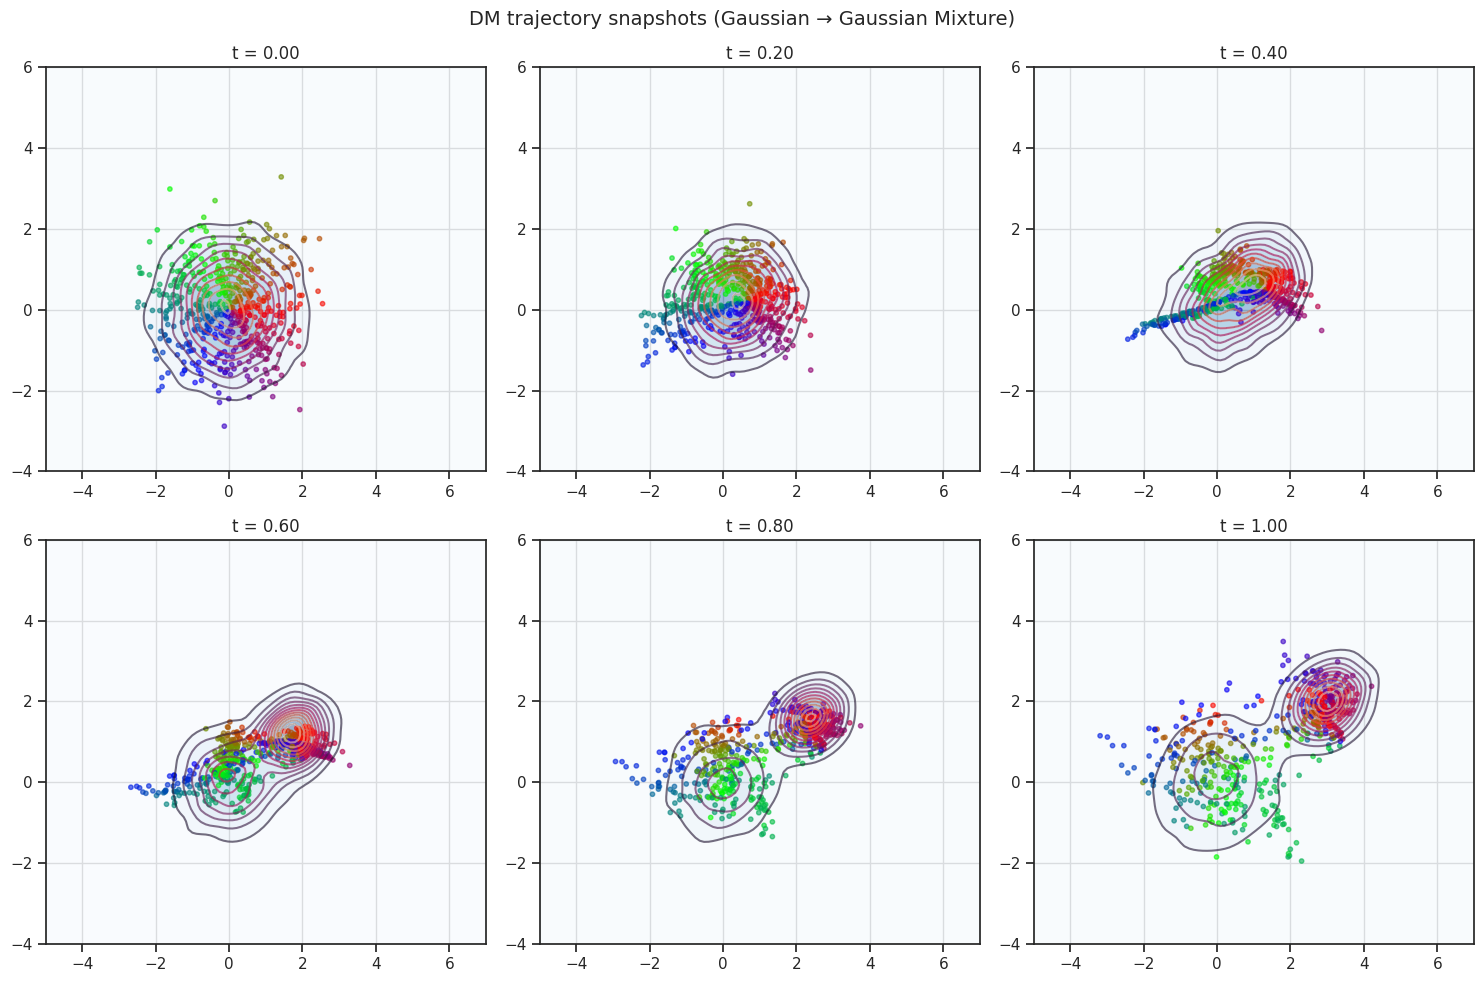

In [11]:
# ── 1. Trajectory snapshots ──────────────────────────────────────────────────

desired_times = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
indices       = [np.argmin(np.abs(time_pts - tv)) for tv in desired_times]
point_colors  = get_angle_colors(x0_np)

xx, yy  = np.mgrid[-5:7:100j, -4:6:100j]
grid_pts = np.vstack([xx.ravel(), yy.ravel()])

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('DM trajectory snapshots (Gaussian → Gaussian Mixture)', fontsize=14)

for i, idx in enumerate(indices):
    ax  = axes[i // 3, i % 3]
    t   = time_pts[idx]
    x_t = trajectory[idx]

    x1_ref   = mixture.sample_np(5000)
    eps      = np.random.randn(5000, 2)
    x_fwd    = t * x1_ref + (1 - t) * eps
    kernel   = gaussian_kde(x_fwd.T)
    density  = kernel(grid_pts).reshape(xx.shape)

    ax.contourf(xx, yy, density, levels=12, cmap='Blues', alpha=0.4)
    ax.contour (xx, yy, density, levels=12, alpha=0.6)
    ax.scatter(x_t[:, 0], x_t[:, 1], c=point_colors, alpha=0.6, s=10)
    ax.set_title(f't = {t:.2f}')
    ax.set_xlim(-5, 7); ax.set_ylim(-4, 6)
    ax.grid(True)

plt.tight_layout()
plt.show()



In [12]:
# ── 2. Thermodynamic analogy ──────────────────────────────────────────────────

def volume(x):
    cov = np.cov(x.T)
    return float(np.sqrt(np.linalg.det(cov)))

def temperature(v):
    return float(np.mean(np.sum(v**2, axis=1)))

volumes, temps, pressures, energies = [], [], [], []

for i, t in enumerate(time_pts):
    x = trajectory[i]
    v = velocity_const

    V = volume(x)
    T = temperature(v)
    P = T / V if V > 1e-8 else np.nan

    volumes.append(V)
    temps.append(T)
    pressures.append(P)
    energies.append(np.mean(np.sum(v**2, axis=1) / 2))

V_arr = np.array(volumes)
T_arr = np.array(temps)
P_arr = np.array(pressures)
E_arr = np.array(energies)

dV = np.diff(V_arr); dT = np.diff(T_arr); dP = np.diff(P_arr)



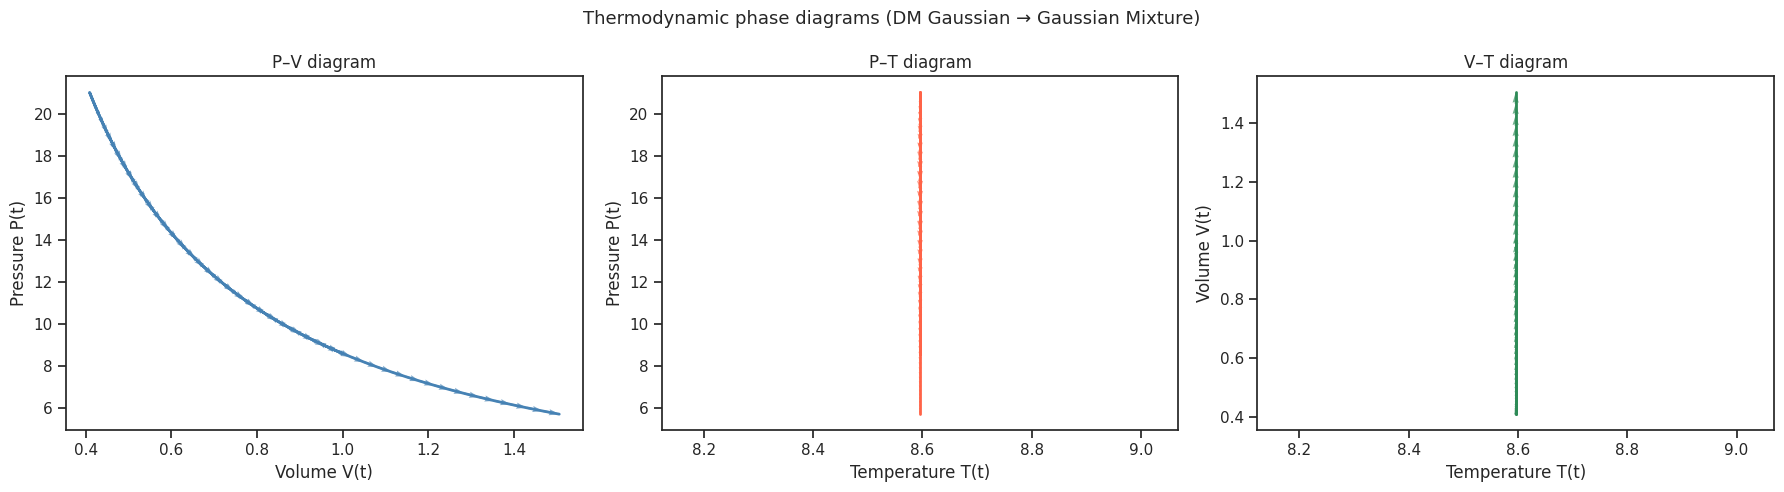

In [13]:
# ── 2a. Phase diagrams ───────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Thermodynamic phase diagrams (DM Gaussian → Gaussian Mixture)', fontsize=13)

arrow_kw = dict(angles='xy', scale_units='xy', scale=1, width=0.004, color='steelblue', alpha=0.7)

# P–V
ax = axes[0]
ax.plot(V_arr, P_arr, lw=2, color='steelblue')
ax.quiver(V_arr[:-1], P_arr[:-1], dV, dP, **arrow_kw)
ax.set_xlabel('Volume V(t)'); ax.set_ylabel('Pressure P(t)')
ax.set_title('P–V diagram')

# P–T
ax = axes[1]
ax.plot(T_arr, P_arr, lw=2, color='tomato')
ax.quiver(T_arr[:-1], P_arr[:-1], dT, dP, **{**arrow_kw, 'color': 'tomato'})
ax.set_xlabel('Temperature T(t)'); ax.set_ylabel('Pressure P(t)')
ax.set_title('P–T diagram')

# V–T
ax = axes[2]
ax.plot(T_arr, V_arr, lw=2, color='seagreen')
ax.quiver(T_arr[:-1], V_arr[:-1], dT, dV, **{**arrow_kw, 'color': 'seagreen'})
ax.set_xlabel('Temperature T(t)'); ax.set_ylabel('Volume V(t)')
ax.set_title('V–T diagram')

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, 'phase_diagrams.png'), dpi=120)
plt.show()



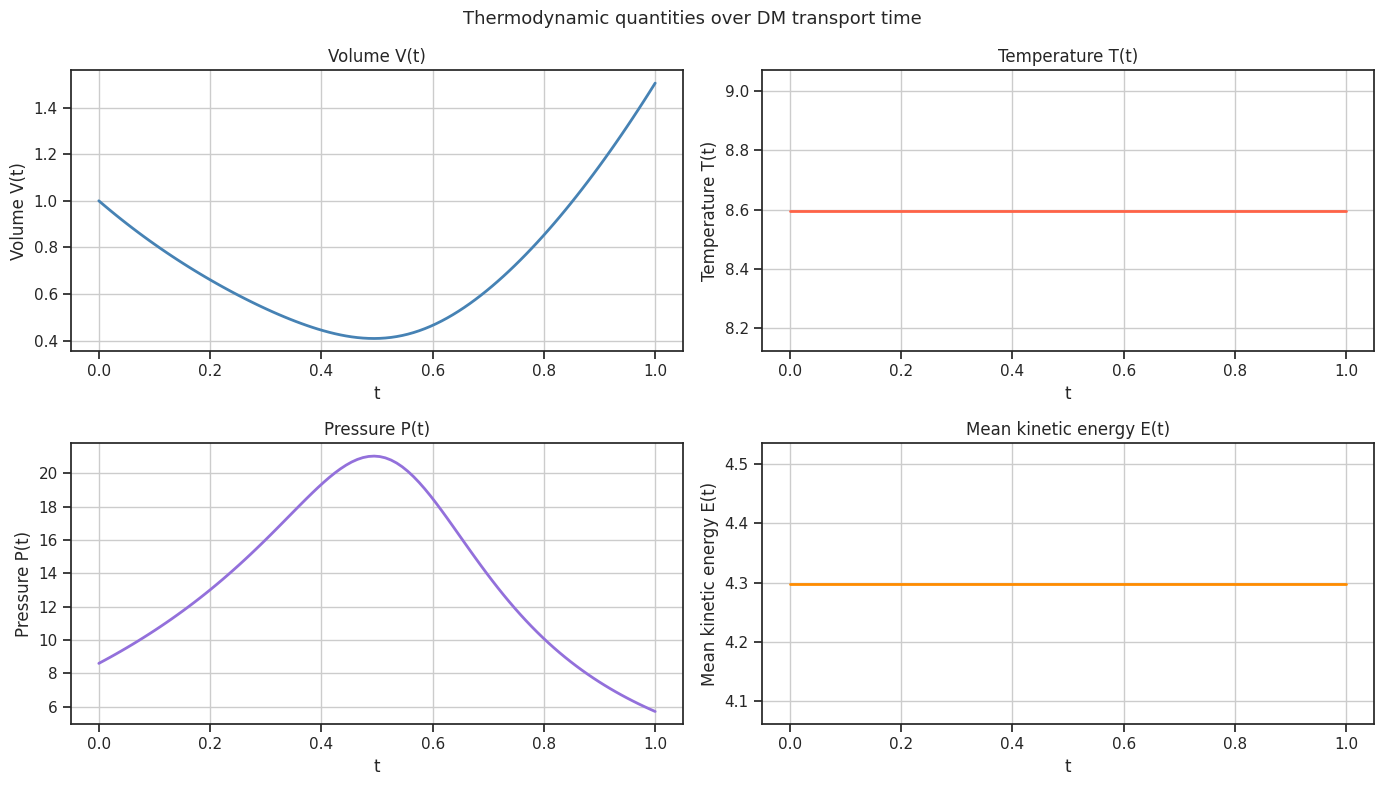

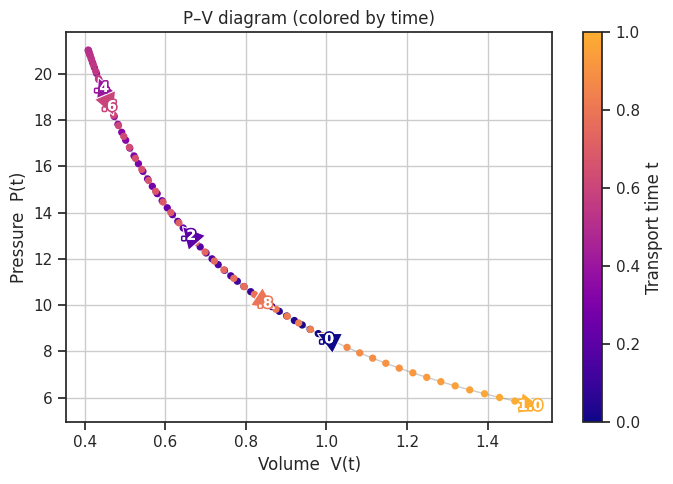

In [14]:
# ── 2b. Individual time-series ───────────────────────────────────────────────

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('Thermodynamic quantities over DM transport time', fontsize=13)

for ax, y, label, color in zip(
        axes.ravel(),
        [V_arr,  T_arr,         P_arr,      E_arr],
        ['Volume V(t)', 'Temperature T(t)', 'Pressure P(t)', 'Mean kinetic energy E(t)'],
        ['steelblue', 'tomato', 'mediumpurple', 'darkorange']
):
    ax.plot(time_pts, y, lw=2, color=color)
    ax.set_xlabel('t'); ax.set_ylabel(label)
    ax.set_title(label); ax.grid(True)

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, 'thermo_timeseries.png'), dpi=120)
plt.show()


# ── 2c. Annotated P–V ────────────────────────────────────────────────────────

from matplotlib.markers import MarkerStyle
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap as LSC

# Truncate plasma to avoid the unreadable yellow end (t=1)
cmap = LSC.from_list('', plt.cm.plasma(np.linspace(0.0, 0.82, 256)))

tick_times   = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
tick_indices = [np.argmin(np.abs(time_pts - tv)) for tv in tick_times]

fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(V_arr, P_arr, c=time_pts, cmap=cmap, s=18, zorder=3)
ax.plot(V_arr, P_arr, lw=1, alpha=0.4, color='grey')
plt.colorbar(sc, ax=ax, label='Transport time t')
ax.set_xlabel('Volume  V(t)'); ax.set_ylabel('Pressure  P(t)')
ax.set_title('P–V diagram (colored by time)')
ax.grid(True)
plt.tight_layout()

for idx in tick_indices:
    t_val  = time_pts[idx]
    v, p_  = V_arr[idx], P_arr[idx]
    next_i = min(idx + 1, len(V_arr) - 1)
    prev_i = max(idx - 1, 0)
    dv = V_arr[next_i] - V_arr[prev_i]
    dp = P_arr[next_i] - P_arr[prev_i]

    origin   = ax.transData.transform([v, p_])
    tip      = ax.transData.transform([v + dv, p_ + dp])
    ddx, ddy = tip - origin
    angle    = np.degrees(np.arctan2(ddy, ddx))

    color = cmap(t_val)
    m = MarkerStyle('^')
    m._transform = m.get_transform().rotate_deg(angle - 90)
    ax.plot(v, p_, marker=m, markersize=16, color=color, zorder=6,
            markeredgecolor='white', markeredgewidth=0.8, linestyle='none')

    # Label with white stroke so it reads on any background
    ann = ax.annotate(
        f'{t_val:.1f}' if t_val >= 1.0 else f'{t_val:.1f}'[1:], xy=(v, p_), xytext=(0, -1),
        textcoords='offset points', fontsize=10, fontweight='bold',
        color='white', ha='center', va='center', zorder=7,
    )
    ann.set_path_effects([
        pe.withStroke(linewidth=2.5, foreground=color),
        pe.Normal(),
    ])

plt.show()



Fréchet Distance (2D): 0.083953


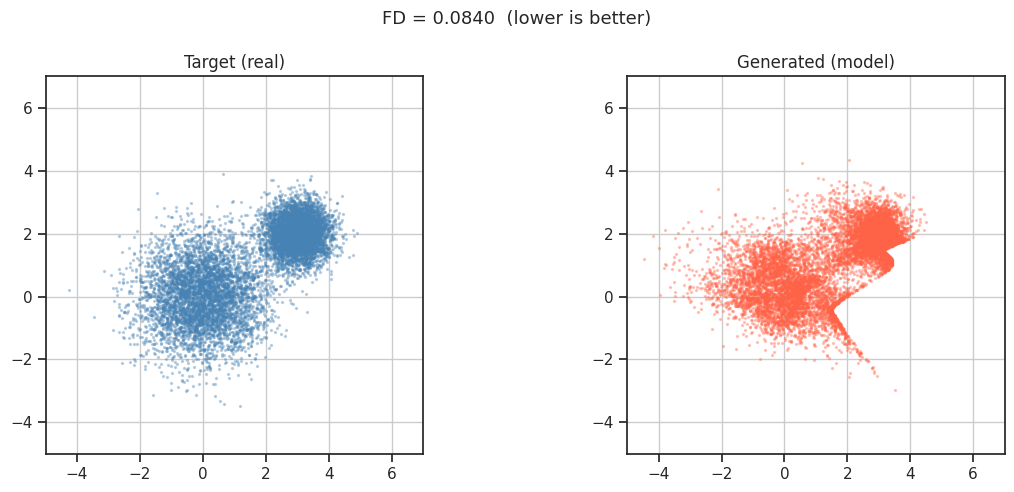

In [15]:
# ── 3. Fréchet Distance (2D FID) ──────────────────────────────────────────────
# Since this is a 2D toy problem (no images), we compute the Fréchet distance
# directly on raw sample features instead of Inception embeddings.
# Formula: FD = ||μ_r - μ_g||² + Tr(Σ_r + Σ_g - 2·(Σ_r Σ_g)^½)

from scipy.linalg import sqrtm

def frechet_distance(real_samples, gen_samples):
    """Fréchet distance between two sets of samples (any dimension)."""
    mu_r = real_samples.mean(axis=0)
    mu_g = gen_samples.mean(axis=0)
    sigma_r = np.cov(real_samples, rowvar=False)
    sigma_g = np.cov(gen_samples, rowvar=False)

    diff = mu_r - mu_g
    # Matrix square root of Σ_r @ Σ_g
    covmean = sqrtm(sigma_r @ sigma_g)
    # Numerical noise can cause tiny imaginary parts — discard them
    if np.iscomplexobj(covmean):
        covmean = covmean.real

    fd = diff @ diff + np.trace(sigma_r + sigma_g - 2 * covmean)
    return float(fd)


N_FD = 10_000

model.eval()
with torch.no_grad():
    x_src = source_sampler.sample(N_FD).to(DEVICE)
    x_gen = model(x_src).cpu().numpy()

x_real = target_sampler.sample_np(N_FD)

fd = frechet_distance(x_real, x_gen)
print(f"Fréchet Distance (2D): {fd:.6f}")

# ── Visual sanity check ───────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle(f'FD = {fd:.4f}  (lower is better)', fontsize=13)

for ax, pts, label, color in zip(
    axes,
    [x_real, x_gen],
    ['Target (real)', 'Generated (model)'],
    ['steelblue', 'tomato'],
):
    ax.scatter(pts[:, 0], pts[:, 1], s=2, alpha=0.3, color=color)
    ax.set_title(label)
    ax.set_xlim(-5, 7); ax.set_ylim(-5, 7)
    ax.set_aspect('equal'); ax.grid(True)

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, 'fd_comparison.png'), dpi=120)
plt.show()
